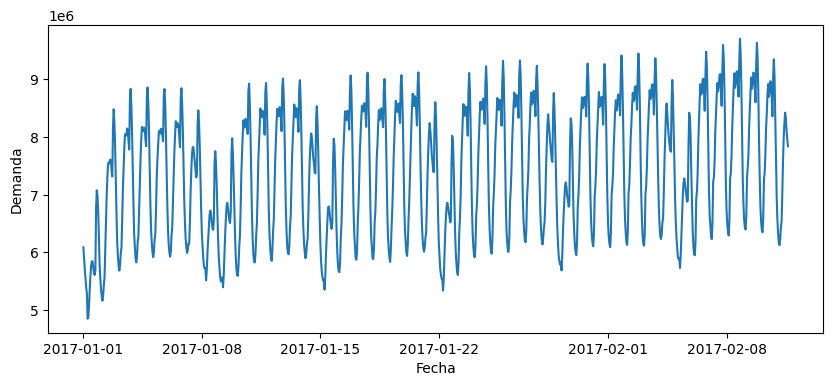

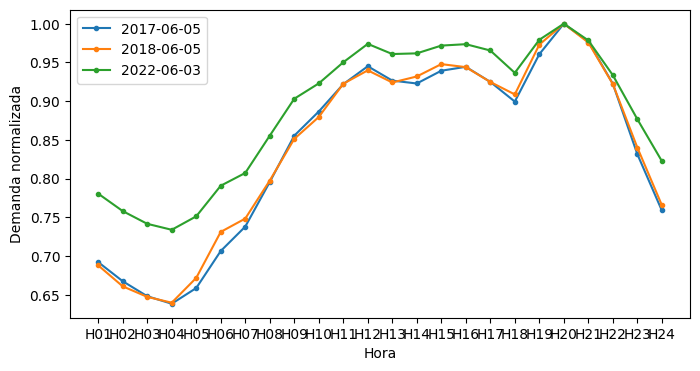

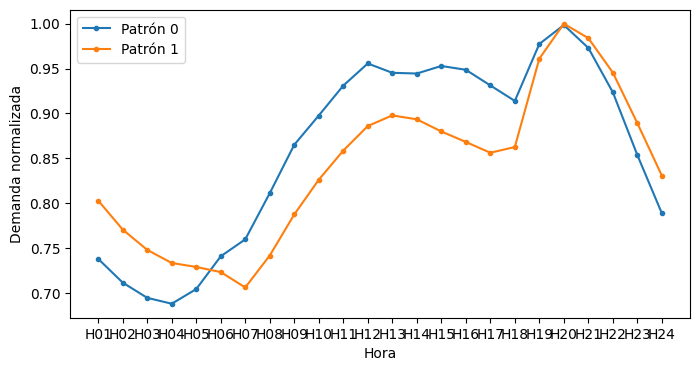

Cluster 0


day_of_week
Lunes        229
Martes       283
Miércoles    284
Jueves       284
Viernes      278
Sábado       267
Domingo        0
Name: count, dtype: int64

Cluster 1


day_of_week
Lunes         67
Martes        13
Miércoles     12
Jueves        11
Viernes       17
Sábado        28
Domingo      296
Name: count, dtype: int64

In [9]:
# ¿Qué patrones diarios de demanda comercial aparecen al comparar la forma de sus perfiles horarios?

import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv("../data/demanda_comercial.csv.gz", compression="gzip")
data = data.dropna().drop_duplicates().set_index("Fecha")
data.index = pd.to_datetime(data.index)
hours = data.columns.tolist()
data.head()


  # ---

# La tabla ancha se convierte en fecha, hora y demanda para evidenciar el nivel de la serie en el tiempo.

series = data.reset_index().melt(
    id_vars="Fecha",
    value_vars=hours,
    var_name="hora",
    value_name="demanda",
)
series["hora"] = series["hora"].str.removeprefix("H").astype(int)
series["instante"] = series["Fecha"] + pd.to_timedelta(series["hora"] - 1, unit="h")
series = series.sort_values("instante").head(1000)
series.head()

plt.figure(figsize=(10, 4))
plt.plot(series["instante"], series["demanda"])
plt.xlabel("Fecha")
plt.ylabel("Demanda")
plt.savefig("../submission/demanda-comercial.png", bbox_inches="tight")
plt.show()
# ---

# La normalización separa la forma diaria del nivel absoluto de demanda.

profiles = data.div(data.max(axis=1), axis=0)
profiles.head()

# ---

# Los perfiles de días comparables muestran por qué conviene agrupar formas y no niveles.

plt.figure(figsize=(8, 4))
for date in ["2017-06-05", "2018-06-05", "2022-06-03"]:
    plt.plot(hours, profiles.loc[date], marker=".", label=date)
plt.xlabel("Hora")
plt.ylabel("Demanda normalizada")
plt.legend()
plt.savefig("../submission/demanda-comercial-patrones-ejemplo.png", bbox_inches="tight")
plt.show()

# ---

# La silueta contrasta alternativas de segmentación de los perfiles diarios.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows=[]
for n_clusters in range(2, 6):
    model=KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit(profiles)
    rows.append({"n_clusters": n_clusters, "silhouette_score": silhouette_score(profiles, model.labels_)})
cluster_selection=pd.DataFrame(rows)
cluster_selection


# ---

# Dos patrones maximizan la silueta y permiten una interpretación inicial de los perfiles.

kmeans=KMeans(n_clusters=2, n_init=10, random_state=0).fit(profiles)
plt.figure(figsize=(8, 4))
for cluster, center in enumerate(kmeans.cluster_centers_):
    plt.plot(hours, center, marker=".", label=f"Patrón {cluster}")
plt.xlabel("Hora")
plt.ylabel("Demanda normalizada")
plt.legend()
plt.savefig("../submission/demanda-comercial-perfiles.png", bbox_inches="tight")
plt.show()



# ---

# Las asignaciones se conservan para contar su frecuencia por día de semana; un cluster no identifica de forma determinista un día.

day_names = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
daily_patterns = pd.DataFrame({"Fecha": profiles.index, "cluster": kmeans.labels_})
daily_patterns["day_of_week"] = pd.Categorical(
    pd.to_datetime(daily_patterns["Fecha"]).dt.dayofweek.map(dict(enumerate(day_names))),
    categories=day_names,
    ordered=True,
)
daily_patterns


# ---


# Los conteos ordenados revelan el patrón semanal emergente dentro de cada cluster sin convertirlo en una regla fija.

for cluster in [0, 1]:
    day_counts = (
        daily_patterns.loc[daily_patterns["cluster"] == cluster, "day_of_week"]
        .value_counts()
        .reindex(day_names, fill_value=0)
    )
    print(f"Cluster {cluster}")
    display(day_counts)

days_cluster_0 = (
    daily_patterns.loc[daily_patterns["cluster"] == 0, "day_of_week"]
    .value_counts()
    .reindex(day_names, fill_value=0)
)
days_cluster_1 = (
    daily_patterns.loc[daily_patterns["cluster"] == 1, "day_of_week"]
    .value_counts()
    .reindex(day_names, fill_value=0)
)



# ---

# Se guardan las evidencias de la segmentación para discutir la interpretación durante la clase.

from pathlib import Path
output=Path("../submission")
cluster_selection.to_csv(output / "cluster-selection.csv", index=False)
daily_patterns.to_csv(output / "demanda-comercial-clusters.csv", index=False)
day_summary=pd.DataFrame({"day_of_week": day_names, "cluster_0_days": days_cluster_0, "cluster_1_days": days_cluster_1})
day_summary.to_csv(output / "demanda-comercial-dias.csv", index=False)
pd.DataFrame({"Fecha": [profiles.index[-1]], "cluster_asignado": [kmeans.predict(profiles.iloc[[-1]])[0]]}).to_csv(output / "perfil-recibido.csv", index=False)

In [10]:
# Se guardan las evidencias de la segmentación para discutir la interpretación durante la clase.

from pathlib import Path
output=Path("../submission")
cluster_selection.to_csv(output / "cluster-selection.csv", index=False)
daily_patterns.to_csv(output / "demanda-comercial-clusters.csv", index=False)
day_summary=pd.DataFrame({"day_of_week": day_names, "cluster_0_days": days_cluster_0, "cluster_1_days": days_cluster_1})
day_summary.to_csv(output / "demanda-comercial-dias.csv", index=False)
pd.DataFrame({"Fecha": [profiles.index[-1]], "cluster_asignado": [kmeans.predict(profiles.iloc[[-1]])[0]]}).to_csv(output / "perfil-recibido.csv", index=False)